In [ ]:
#import
import numpy as np
import matplotlib.pyplot as plt


import pickle as pk
from nilearn import plotting

import sys
sys.path.append('src/')

from hcp_IO import load_ts_schaefer300_dict, load_ts_aal89_dict, load_scaffold
from utils import threshold_matrix



%load_ext autoreload
%autoreload 2

#from visualize import threshold_adj_matrix

#paths
sup_folder = "/data/shared/"
ts_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/ts/RL/"
fc_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/fc/whole/"
sc_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/scaffolds/whole/freq/"
figure_folder = "../figures/final/fig1/"

# AAL89 paths
aal89_data_dir = sup_folder + "HCP/100unrelated/aal89/"
aal89_ts_folder = aal89_data_dir + "ts/TimeSeriesAAL/"
aal89_fc_folder = aal89_data_dir + "fc/whole/"
aal89_sc_folder = aal89_data_dir + "scaffolds/whole/freq/"

In [2]:
## LOAD TS DATA ##

ts_data = load_ts_schaefer300_dict(ts_folder)
print('The dataset is composed of ' + str(len(ts_data.keys())) + ' subjects')
print('Each subject performed ' + str(len(ts_data['103414'].keys())) + ' trials')
print('Each trial contains ' + str(ts_data['103414'][0].shape[1]) +' time series (number of brain regions)')
print('The lenght of each time serie is ' + str(ts_data['103414'][0].shape[0]) + ' time points')


  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:13<00:00, 15.18it/s]

The dataset is composed of 100 subjects
Each subject performed 2 trials
Each trial contains 300 time series (number of brain regions)
The lenght of each time serie is 1200 time points


### Panel A

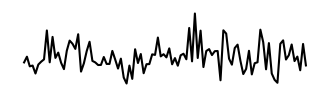

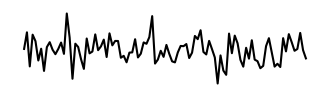

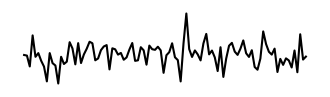

In [4]:
subjects = list(ts_data.keys())[:3]

i=1
for subject in subjects:
    plt.figure(figsize=(4,1))
    plt.plot(ts_data[subject][0].T[9,:100], c='k')
    plt.axis('off')
    plt.savefig(figure_folder + f'fig4A_timeseries{i}.png', transparent=True, dpi=300)
    i += 1
    plt.show()



# plt.figure(figsize=(4,1))
# plt.plot(ts_data[subject][1].T[9,:100], c='violet', alpha=0.7)
# plt.axis('off')

# plt.savefig('fig1_timeseries3.png', transparent=True, dpi=300)
# plt.show()

The dictionary contains the funcional connectivity matrix for 100 subjects, undergoing 2 trials each.
Functional connectivity matrix dimension is 300x300


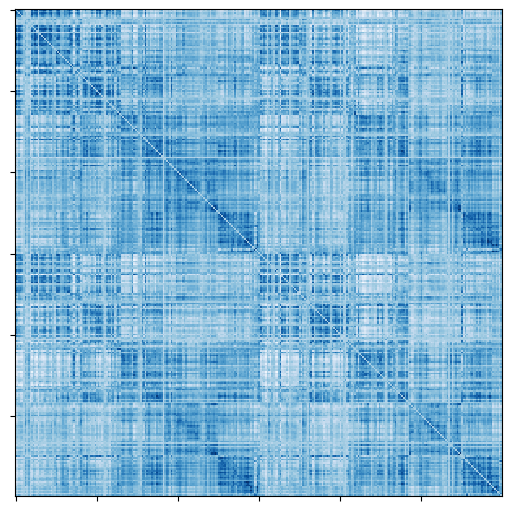

In [5]:
subject = '100307'

## LOAD FC DATA ##

with open(fc_folder + "whole_corrs.pck", "rb") as f:
    fc_data = pk.load(f)

print('The dictionary contains the funcional connectivity matrix for ' + str(len(fc_data.keys())) + ' subjects, undergoing ' + str(len(fc_data[subject].keys())) + ' trials each.')
print('Functional connectivity matrix dimension is ' + str(fc_data['103414'][0].shape[0]) + 'x' + str(fc_data['103414'][0].shape[1]))

np.fill_diagonal(fc_data[subject][1], 0)
plotting.plot_matrix(fc_data[subject][1], colorbar=False, cmap='Blues')
plt.savefig(figure_folder + 'fig1B.png', transparent=True, dpi=300)
plt.show()

### Panel C

In [6]:
## LOAD AAL89 TS DATA ##

ts_aal89_data = load_ts_aal89_dict(aal89_ts_folder)
print('The AAL89 dataset is composed of ' + str(len(ts_aal89_data.keys())) + ' subjects')
if '103414' in ts_aal89_data and 0 in ts_aal89_data['103414']:
    print('Each subject performed ' + str(len(ts_aal89_data['103414'].keys())) + ' trials')
    print('Each trial contains ' + str(ts_aal89_data['103414'][0].shape[1] if ts_aal89_data['103414'][0].ndim > 1 else 89) +' time series (number of brain regions)')
    print('The length of each time series is ' + str(ts_aal89_data['103414'][0].shape[0]) + ' time points')
else:
    print('Data structure available in the AAL89 atlas')

100%|██████████| 200/200 [00:06<00:00, 28.93it/s]

The AAL89 dataset is composed of 100 subjects
Each subject performed 2 trials
Each trial contains 89 time series (number of brain regions)
The length of each time series is 1200 time points


The dictionary contains the funcional connectivity matrix for 100 subjects, undergoing 2 trials each.
Functional connectivity matrix dimension is 89x89


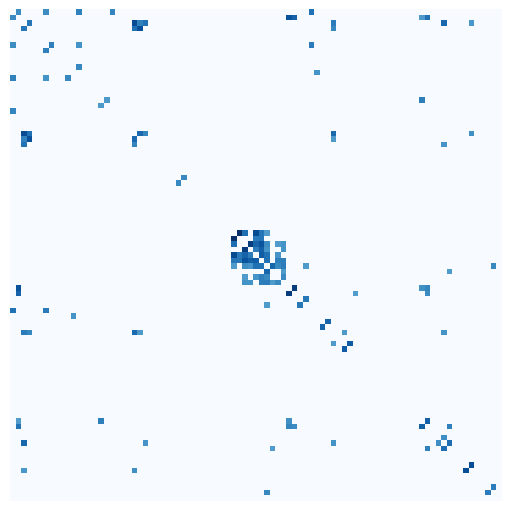

In [13]:
subject = '100307'

## LOAD FC DATA ##

with open(aal89_fc_folder + "whole_corrs.pck", "rb") as f:
    fc_data = pk.load(f)

print('The dictionary contains the funcional connectivity matrix for ' + str(len(fc_data.keys())) + ' subjects, undergoing ' + str(len(fc_data[subject].keys())) + ' trials each.')
print('Functional connectivity matrix dimension is ' + str(fc_data['103414'][0].shape[0]) + 'x' + str(fc_data['103414'][0].shape[1]))

np.fill_diagonal(fc_data[subject][1], 0)
thresholded = threshold_matrix(fc_data[subject][1], perc_to_keep=2)
plotting.plot_matrix(thresholded, colorbar=False, cmap='Blues', vmin=0.5)
plt.savefig(figure_folder + 'fig1C_FC.png', transparent=True, dpi=300)
plt.axis('off')
plt.show()

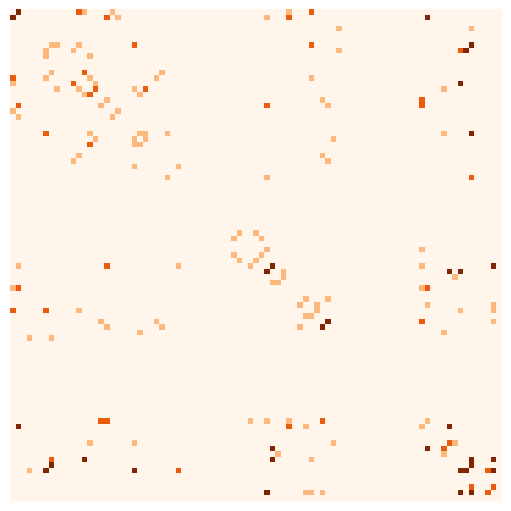

In [14]:
#Plot aal scaffold in Oranges
subject = '100307'

aal89_scaffold = load_scaffold(aal89_sc_folder)

np.fill_diagonal(aal89_scaffold[subject][1], 0)
plotting.plot_matrix(aal89_scaffold[subject][1], colorbar=False, cmap='Oranges', vmin=0, vmax=3)
plt.savefig(figure_folder + 'fig1C_SC.png', transparent=True, dpi=300)
plt.axis('off')
plt.show()